In [8]:
import polars as pl
import matplotlib.pyplot as plt
import numpy as np 

%matplotlib widget

data_dir = "data_complete"

In [15]:
data_tau = pl.read_parquet(f"{data_dir}/tau.parquet")

In [16]:
results_tau = data_tau.group_by(
    pl.col('f')
).agg(
    pl.col('pow1').max().alias('pow1max'),
    pl.col('Rload')
)

In [17]:
Ropt_tau = []
for f in (results_tau["f"]):
        p = results_tau.filter(pl.col("f") == f)["pow1max"]
        d = data_tau.filter((pl.col("f")==f) & (pl.col("pow1") == p))["Rload"]
        Ropt_tau.append(d)


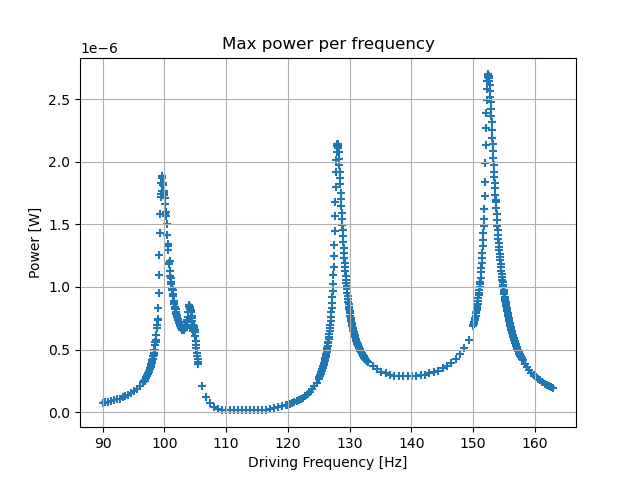

In [18]:
plt.figure()
plt.scatter(results_tau["f"], results_tau["pow1max"], marker='+')
plt.xlabel("Driving Frequency [Hz]")
plt.ylabel("Power [W]")
plt.title("Max power per frequency")
plt.grid()
plt.show()

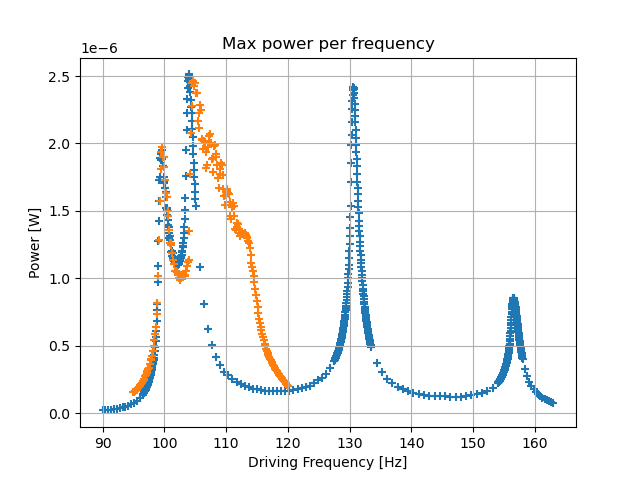

In [9]:
plt.figure()
plt.scatter(results_coupled["f"], results_coupled["pow1max"], marker='+')
plt.scatter(results_capa["f"], results_capa["pow2max"], marker='+')
plt.xlabel("Driving Frequency [Hz]")
plt.ylabel("Power [W]")
plt.title("Max power per frequency")
plt.grid()
plt.show()

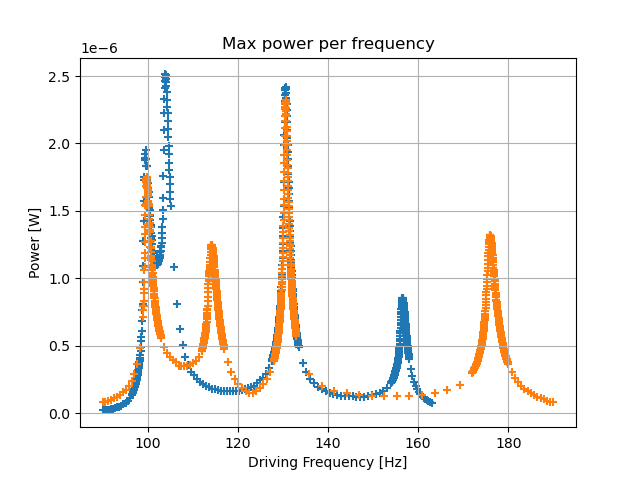

In [16]:
plt.figure()
plt.scatter(results_coupled["f"], results_coupled["pow1max"], marker='+', label="coupled")
plt.scatter(results_uncoupled["f"], results_uncoupled["powtot"], marker='+', label = "uncoupled")
# plt.scatter(results_capa["f"], results_capa["pow2max"], marker='+', label = "capa")
plt.xlabel("Driving Frequency [Hz]")
plt.ylabel("Power [W]")
plt.title("Max power per frequency")
plt.grid()
plt.show()

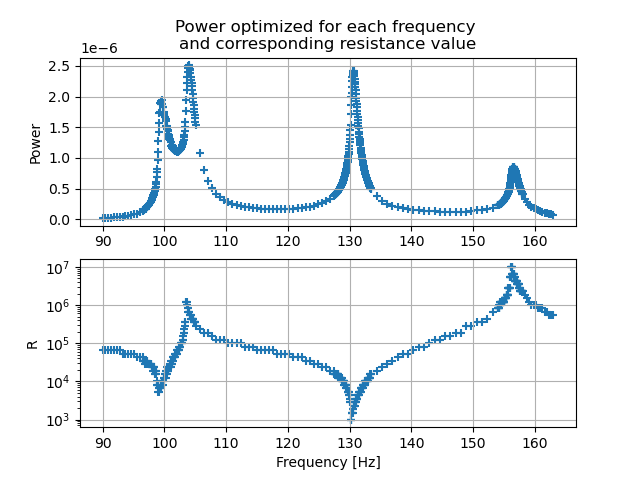

In [11]:
plt.figure()
plt.subplot(2, 1, 1)
plt.scatter(results_coupled["f"], results_coupled["pow1max"], marker='+', label = "coupled")
# plt.scatter(results_uncoupled["f"], results_uncoupled["pow1max"], marker='+', label = "uncoupled")
plt.title('Power optimized for each frequency \nand corresponding resistance value')
plt.ylabel('Power')
plt.grid()

plt.subplot(2, 1, 2)
plt.scatter(results_coupled["f"], Ropt_coupled, marker='+', label = "coupled")
# plt.scatter(results_uncoupled["f"], Ropt_uncoupled_1, marker='+', label = "uncoupled")
# plt.scatter(results_uncoupled["f"], Ropt_uncoupled_2, marker='+', label = "uncoupled")
plt.ylabel('R')
plt.yscale('log')
plt.xlabel('Frequency [Hz]')
plt.grid()

plt.show()

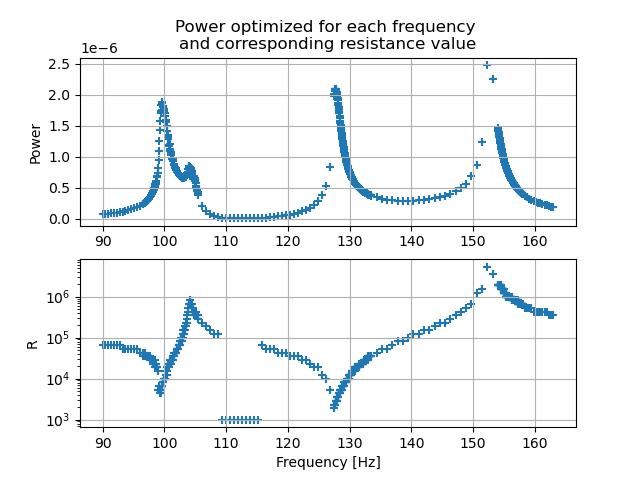

In [12]:
plt.figure()
plt.subplot(2, 1, 1)
plt.scatter(results_tau["f"], results_tau["pow1max"], marker='+', label = "coupled")
plt.title('Power optimized for each frequency \nand corresponding resistance value')
plt.ylabel('Power')
plt.grid()

plt.subplot(2, 1, 2)
plt.scatter(results_tau["f"], Ropt_tau, marker='+', label = "coupled")
plt.ylabel('R')
plt.yscale('log')
plt.xlabel('Frequency [Hz]')
plt.grid()

plt.show()

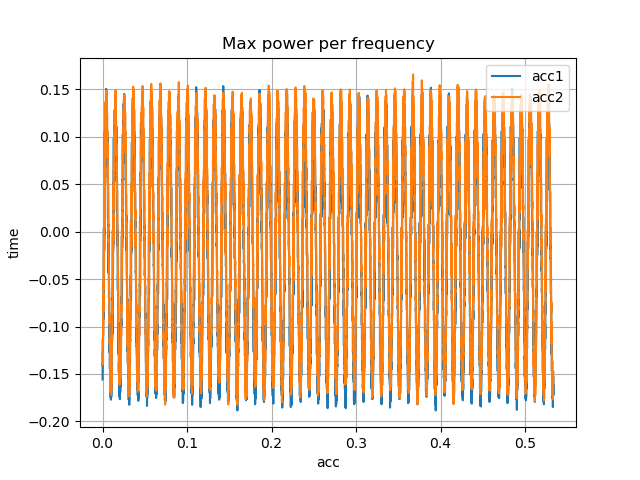

In [13]:
plt.figure()
plt.plot(data_coupled["time_meas"][8], data_coupled["acc1_temp"][8], label= "acc1")
plt.plot(data_coupled["time_meas"][8], data_coupled["acc2_temp"][8], label= "acc2")
plt.xlabel("acc")
plt.ylabel("time")
plt.title("Max power per frequency")
plt.legend()
plt.grid()
plt.show()

In [14]:
print(np.degrees(data_coupled["phase_shift"][2]))

0.5374018027303694


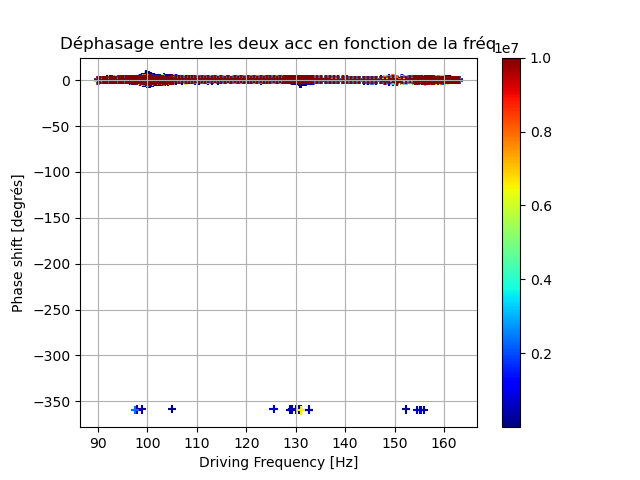

In [15]:
plt.figure()
plt.scatter(data_coupled["f"], np.degrees(data_coupled["phase_shift"]), c = data_coupled['Rload'], marker='+', cmap = 'jet')
plt.colorbar()
plt.xlabel("Driving Frequency [Hz]")
plt.ylabel("Phase shift [degrés]")
plt.title("Déphasage entre les deux acc en fonction de la fréq")
plt.grid()
plt.show()